# PROJETO DE COLETA DE DADOS
## Clima nas capitais brasileiras

**Autor:** Julio Cesar Galdino Vieira
**Matrícula:** CP3044645
**Polo:** São José dos Campos/SP
**Data:** 09/11/2026
**Disciplina:** Introdução à Ciência de Dados

---

## 1. OBJETIVO

Comparar o clima recente das 27 capitais brasileiras. A coleta reúne um ano de dados diários de temperatura, chuva, vento e insolação, de 9 de novembro de 2025 a 8 de novembro de 2026, para ver como as cinco regiões se separam no calor, no frio e no calendário da chuva.

O tema está na lista sugerida da disciplina (Clima, Open-Meteo, API).

## 2. FONTES DE DADOS

| Fonte | URL | Método | Dados coletados |
|-------|-----|--------|-----------------|
| Open-Meteo Historical Weather API | https://archive-api.open-meteo.com/v1/archive | API | Temperatura máxima, mínima e média; precipitação; chuva; vento máximo a 10 m; insolação. Série diária, 27 capitais, 365 dias. |

A série vem da reanálise ERA5, entregue pela Open-Meteo. A API é pública e não pede chave. As coordenadas são o centro de cada capital. A resposta devolve o ponto de grade mais próximo e o fuso `America/Sao_Paulo`.

## 3. METODOLOGIA

Uma requisição por capital. O intervalo pedido foi de 2025-11-09 a 2026-11-08: 365 dias. Cada mês do calendário entra uma vez, com a quantidade certa de dias. Novembro junta o fim de 2025 (a partir do dia 9) e o começo de 2026 (até o dia 8).

Houve uma pausa de 0,3 s entre as chamadas. A resposta bruta foi gravada em `dados/clima_capitais_bruto.csv`.


In [1]:
import json
import time
import urllib.parse
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
})

CAPITAIS = [
    ("Rio Branco", "AC", "Norte", -9.9747, -67.8243),
    ("Maceió", "AL", "Nordeste", -9.6658, -35.7353),
    ("Macapá", "AP", "Norte", 0.0356, -51.0705),
    ("Manaus", "AM", "Norte", -3.1190, -60.0217),
    ("Salvador", "BA", "Nordeste", -12.9777, -38.5016),
    ("Fortaleza", "CE", "Nordeste", -3.7172, -38.5433),
    ("Brasília", "DF", "Centro-Oeste", -15.7939, -47.8828),
    ("Vitória", "ES", "Sudeste", -20.3155, -40.3128),
    ("Goiânia", "GO", "Centro-Oeste", -16.6869, -49.2648),
    ("São Luís", "MA", "Nordeste", -2.5387, -44.2825),
    ("Cuiabá", "MT", "Centro-Oeste", -15.6010, -56.0974),
    ("Campo Grande", "MS", "Centro-Oeste", -20.4697, -54.6201),
    ("Belo Horizonte", "MG", "Sudeste", -19.9167, -43.9345),
    ("Belém", "PA", "Norte", -1.4558, -48.4902),
    ("João Pessoa", "PB", "Nordeste", -7.1195, -34.8450),
    ("Curitiba", "PR", "Sul", -25.4284, -49.2733),
    ("Recife", "PE", "Nordeste", -8.0476, -34.8770),
    ("Teresina", "PI", "Nordeste", -5.0892, -42.8019),
    ("Rio de Janeiro", "RJ", "Sudeste", -22.9068, -43.1729),
    ("Natal", "RN", "Nordeste", -5.7793, -35.2009),
    ("Porto Alegre", "RS", "Sul", -30.0346, -51.2177),
    ("Porto Velho", "RO", "Norte", -8.7612, -63.9004),
    ("Boa Vista", "RR", "Norte", 2.8235, -60.6758),
    ("Florianópolis", "SC", "Sul", -27.5954, -48.5480),
    ("São Paulo", "SP", "Sudeste", -23.5505, -46.6333),
    ("Aracaju", "SE", "Nordeste", -10.9472, -37.0731),
    ("Palmas", "TO", "Norte", -10.2491, -48.3243),
]

INICIO = "2025-11-09"
FIM = "2026-11-08"
BASE = "https://archive-api.open-meteo.com/v1/archive"
VARIAVEIS = ",".join([
    "temperature_2m_max",
    "temperature_2m_min",
    "temperature_2m_mean",
    "precipitation_sum",
    "rain_sum",
    "wind_speed_10m_max",
    "sunshine_duration",
])
ORDEM_REGIAO = ["Norte", "Nordeste", "Centro-Oeste", "Sudeste", "Sul"]
CORES = {
    "Norte": "#1b7f4e",
    "Nordeste": "#d4762c",
    "Centro-Oeste": "#b0893e",
    "Sudeste": "#2f5d8c",
    "Sul": "#6b4c9a",
}


def baixar_cidade(cidade, uf, regiao, lat, lon):
    params = urllib.parse.urlencode({
        "latitude": lat,
        "longitude": lon,
        "start_date": INICIO,
        "end_date": FIM,
        "daily": VARIAVEIS,
        "timezone": "America/Sao_Paulo",
        "wind_speed_unit": "kmh",
    })
    url = f"{BASE}?{params}"
    req = urllib.request.Request(url, headers={"User-Agent": "projeto-coleta-pos/1.0"})
    with urllib.request.urlopen(req, timeout=60) as resp:
        payload = json.load(resp)
    diario = payload["daily"]
    return pd.DataFrame({
        "data": diario["time"],
        "cidade": cidade,
        "uf": uf,
        "regiao": regiao,
        "latitude": payload["latitude"],
        "longitude": payload["longitude"],
        "temp_max_c": diario["temperature_2m_max"],
        "temp_min_c": diario["temperature_2m_min"],
        "temp_media_c": diario["temperature_2m_mean"],
        "precipitacao_mm": diario["precipitation_sum"],
        "chuva_mm": diario["rain_sum"],
        "vento_max_kmh": diario["wind_speed_10m_max"],
        "insolacao_s": diario["sunshine_duration"],
    })


bruto_path = Path("dados") / "clima_capitais_bruto.csv"
if bruto_path.exists():
    bruto = pd.read_csv(bruto_path)
    print(f"Base local: {bruto_path}")
else:
    partes = []
    for cidade, uf, regiao, lat, lon in CAPITAIS:
        print(f"baixando {cidade}")
        partes.append(baixar_cidade(cidade, uf, regiao, lat, lon))
        time.sleep(0.3)
    bruto = pd.concat(partes, ignore_index=True)
    bruto_path.parent.mkdir(parents=True, exist_ok=True)
    bruto.to_csv(bruto_path, index=False)
    print(f"Salvo em {bruto_path}")

print(f"Registros: {len(bruto)}")
print(f"Capitais: {bruto['cidade'].nunique()}")
print(f"Colunas recebidas: {list(bruto.columns)}")
print(f"Nulos: {int(bruto.isna().sum().sum())}")
print(f"Período: {bruto['data'].min()} a {bruto['data'].max()}")


Base local: dados\clima_capitais_bruto.csv
Registros: 9855
Capitais: 27
Colunas recebidas: ['data', 'cidade', 'uf', 'regiao', 'latitude', 'longitude', 'temp_max_c', 'temp_min_c', 'temp_media_c', 'precipitacao_mm', 'chuva_mm', 'vento_max_kmh', 'insolacao_s']
Nulos: 0
Período: 2025-11-09 a 2026-11-08


### 3.2 Limpeza

A resposta veio sem nulos. A limpeza conferiu três coisas: valor ausente, precipitação negativa e a ordem mínima ≤ média ≤ máxima.

A coluna `chuva_mm` repetiu `precipitacao_mm` em todas as linhas. No período não houve precipitação sólida registrada nessas cidades, então a coluna repetida saiu do conjunto.


In [2]:
nulos = int(bruto.isna().sum().sum())
precip_negativa = int((bruto["precipitacao_mm"] < 0).sum())
ordem_quebrada = int((
    (bruto["temp_min_c"] > bruto["temp_media_c"] + 0.05)
    | (bruto["temp_media_c"] > bruto["temp_max_c"] + 0.05)
).sum())
chuva_repetida = bool((bruto["precipitacao_mm"] == bruto["chuva_mm"]).all())

print(f"Nulos: {nulos}")
print(f"Precipitação negativa: {precip_negativa}")
print(f"Dias com mínima > média ou média > máxima: {ordem_quebrada}")
print(f"chuva_mm idêntica a precipitacao_mm: {chuva_repetida}")

limpo = bruto.drop(columns=["chuva_mm"]).copy()
limpo["data"] = pd.to_datetime(limpo["data"])
print(f"Linhas depois da limpeza: {len(limpo)}")


Nulos: 0
Precipitação negativa: 0
Dias com mínima > média ou média > máxima: 0
chuva_mm idêntica a precipitacao_mm: True
Linhas depois da limpeza: 9855


### 3.3 Processamento

A insolação passou de segundos para horas. A amplitude térmica é a máxima do dia menos a mínima. O mês e o ano saem da data. A estação segue o hemisfério sul: verão (dez–fev), outono (mar–mai), inverno (jun–ago) e primavera (set–nov). Dia chuvoso é o dia com pelo menos 1 mm.

O conjunto final está em `dados/clima_capitais.csv`.


In [3]:
ESTACAO = {
    12: "Verão", 1: "Verão", 2: "Verão",
    3: "Outono", 4: "Outono", 5: "Outono",
    6: "Inverno", 7: "Inverno", 8: "Inverno",
    9: "Primavera", 10: "Primavera", 11: "Primavera",
}

df = limpo.copy()
df["insolacao_h"] = (df["insolacao_s"] / 3600).round(2)
df = df.drop(columns=["insolacao_s"])
df["amplitude_termica_c"] = (df["temp_max_c"] - df["temp_min_c"]).round(2)
df["ano"] = df["data"].dt.year
df["mes"] = df["data"].dt.month
df["estacao"] = df["mes"].map(ESTACAO)
df["dia_chuvoso"] = df["precipitacao_mm"] >= 1

colunas = [
    "data", "cidade", "uf", "regiao", "latitude", "longitude",
    "temp_max_c", "temp_min_c", "temp_media_c", "precipitacao_mm",
    "vento_max_kmh", "insolacao_h", "amplitude_termica_c",
    "ano", "mes", "estacao", "dia_chuvoso",
]
df = df[colunas].sort_values(["cidade", "data"]).reset_index(drop=True)

destino = Path("dados") / "clima_capitais.csv"
destino.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(destino, index=False, date_format="%Y-%m-%d")
tamanho_kb = destino.stat().st_size / 1024

print(f"Registros: {len(df)}")
print(f"Colunas: {df.shape[1]}")
print(f"Período: {df['data'].min().date()} a {df['data'].max().date()}")
print(f"Tamanho: {tamanho_kb:.1f} KB")
print(f"Arquivo: {destino}")
print()
print(df.head(5).to_string(index=False))
print()
print(df.dtypes.to_string())


Registros: 9855
Colunas: 17
Período: 2025-11-09 a 2026-11-08
Tamanho: 1046.4 KB
Arquivo: dados\clima_capitais.csv

      data  cidade uf   regiao   latitude  longitude  temp_max_c  temp_min_c  temp_media_c  precipitacao_mm  vento_max_kmh  insolacao_h  amplitude_termica_c  ano  mes   estacao  dia_chuvoso
2025-11-09 Aracaju SE Nordeste -10.931458 -37.068207        30.3        24.0          27.0              0.0           20.4        12.06                  6.3 2025   11 Primavera        False
2025-11-10 Aracaju SE Nordeste -10.931458 -37.068207        29.2        23.9          26.5              1.2           19.1        12.12                  5.3 2025   11 Primavera         True
2025-11-11 Aracaju SE Nordeste -10.931458 -37.068207        28.5        23.3          26.0              2.2           15.3        12.19                  5.2 2025   11 Primavera         True
2025-11-12 Aracaju SE Nordeste -10.931458 -37.068207        28.5        23.9          26.3              0.5           16.3   

## 4. DATASET FINAL

- **Total de registros:** 9.855
- **Total de colunas:** 17
- **Período:** 09/11/2025 a 08/11/2026
- **Tamanho do arquivo:** 1046.4 KB
- **Arquivo:** `dados/clima_capitais.csv`

### Colunas

| Coluna | Tipo | Descrição |
|--------|------|-----------|
| data | data | Dia da observação |
| cidade | texto | Capital |
| uf | texto | Sigla do estado |
| regiao | texto | Região do IBGE |
| latitude | número | Latitude do ponto de grade (graus) |
| longitude | número | Longitude do ponto de grade (graus) |
| temp_max_c | número | Temperatura máxima do dia (°C) |
| temp_min_c | número | Temperatura mínima do dia (°C) |
| temp_media_c | número | Temperatura média do dia (°C) |
| precipitacao_mm | número | Precipitação do dia (mm) |
| vento_max_kmh | número | Velocidade máxima do vento a 10 m (km/h) |
| insolacao_h | número | Horas de sol |
| amplitude_termica_c | número | Máxima menos mínima (°C) |
| ano | inteiro | Ano |
| mes | inteiro | Mês (1–12) |
| estacao | texto | Estação do ano no hemisfério sul |
| dia_chuvoso | lógico | Verdadeiro quando a precipitação é de pelo menos 1 mm |

## 5. ANÁLISE EXPLORATÓRIA

### 5.1 Estatísticas descritivas

No conjunto das capitais, a temperatura média diária foi **25,1 °C**. A mediana ficou em **26,1 °C**. A média é menor porque os dias frios do Sul puxam a cauda de baixo. A precipitação diária tem mediana de **1,4 mm** e média de **4,8 mm**: a média sobe com os poucos dias de chuva forte. Cerca de **20,5%** dos dias não registraram chuva.


In [4]:
numericas = [
    "temp_max_c", "temp_min_c", "temp_media_c", "amplitude_termica_c",
    "precipitacao_mm", "vento_max_kmh", "insolacao_h",
]
print("Estatísticas diárias — todas as capitais")
print(df[numericas].describe().round(2).to_string())

print("\nTemperatura média diária por região (°C)")
print(
    df.groupby("regiao")["temp_media_c"]
    .agg(["mean", "median", "std", "min", "max"])
    .reindex(ORDEM_REGIAO)
    .round(2)
    .to_string()
)

print("\nPor estação (°C e mm/dia)")
estacao = df.groupby("estacao").agg(
    temp_media=("temp_media_c", "mean"),
    precipitacao_media=("precipitacao_mm", "mean"),
).reindex(["Verão", "Outono", "Inverno", "Primavera"])
print(estacao.round(2).to_string())

resumo = df.groupby(["cidade", "uf", "regiao"], as_index=False).agg(
    temp_media=("temp_media_c", "mean"),
    precipitacao_mm=("precipitacao_mm", "sum"),
    dias_chuvosos=("dia_chuvoso", "sum"),
    amplitude=("amplitude_termica_c", "mean"),
    insolacao_h=("insolacao_h", "mean"),
)
resumo["pct_dias_chuvosos"] = resumo["dias_chuvosos"] / 365 * 100

print("\nCapitais — ano da coleta")
print(
    resumo.sort_values("temp_media", ascending=False)
    .round(2)
    .to_string(index=False)
)

quente = df.loc[df["temp_max_c"].idxmax()]
frio = df.loc[df["temp_min_c"].idxmin()]
chuva = df.loc[df["precipitacao_mm"].idxmax()]
print()
print(f"Máxima absoluta: {quente['temp_max_c']:.1f} °C em {quente['cidade']} ({quente['data'].date()})")
print(f"Mínima absoluta: {frio['temp_min_c']:.1f} °C em {frio['cidade']} ({frio['data'].date()})")
print(f"Maior chuva em 24 h: {chuva['precipitacao_mm']:.1f} mm em {chuva['cidade']} ({chuva['data'].date()})")
print(f"Dias sem chuva: {(df['precipitacao_mm'] == 0).mean() * 100:.1f}%")

print("\nInverno e verão por região (°C)")
comparacao = pd.DataFrame({
    "inverno": df[df["estacao"] == "Inverno"].groupby("regiao")["temp_media_c"].mean(),
    "verao": df[df["estacao"] == "Verão"].groupby("regiao")["temp_media_c"].mean(),
}).reindex(ORDEM_REGIAO)
print(comparacao.round(2).to_string())

print("\nAmplitude média por região (°C)")
print(df.groupby("regiao")["amplitude_termica_c"].mean().reindex(ORDEM_REGIAO).round(2).to_string())

print("\nChuva média diária em agosto (mm)")
agosto = df[df["mes"] == 8].groupby("regiao")["precipitacao_mm"].mean()
print(agosto.reindex(ORDEM_REGIAO).round(2).to_string())


Estatísticas diárias — todas as capitais
       temp_max_c  temp_min_c  temp_media_c  amplitude_termica_c  precipitacao_mm  vento_max_kmh  insolacao_h
count     9855.00     9855.00       9855.00              9855.00          9855.00        9855.00      9855.00
mean        29.14       21.84         25.10                 7.31             4.83          15.36        10.05
std          3.92        3.82          3.67                 2.74             8.22           4.58         2.77
min         10.10        2.20          7.30                 1.00             0.00           3.40         0.00
25%         27.40       20.00         23.70                 5.10             0.20          12.00         9.53
50%         29.50       23.30         26.10                 6.90             1.40          14.90        11.01
75%         31.50       24.30         27.40                 9.10             5.70          18.40        11.77
max         40.00       28.60         34.20                18.00           114.

### 5.2 Visualizações

Os quatro gráficos abaixo mostram a temperatura por região, a chuva acumulada de cada capital e o calendário mensal de temperatura e de chuva.


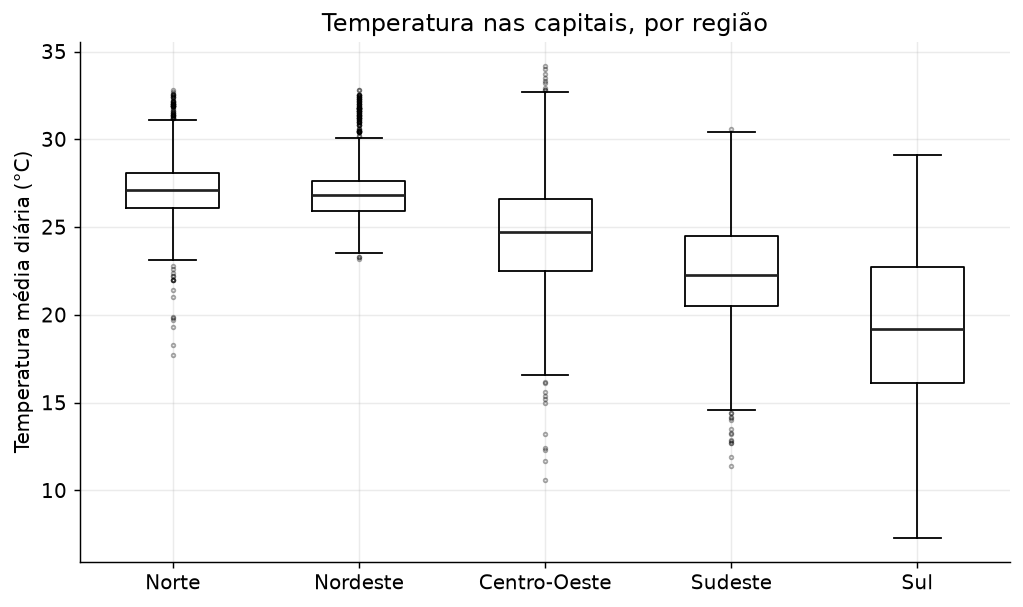

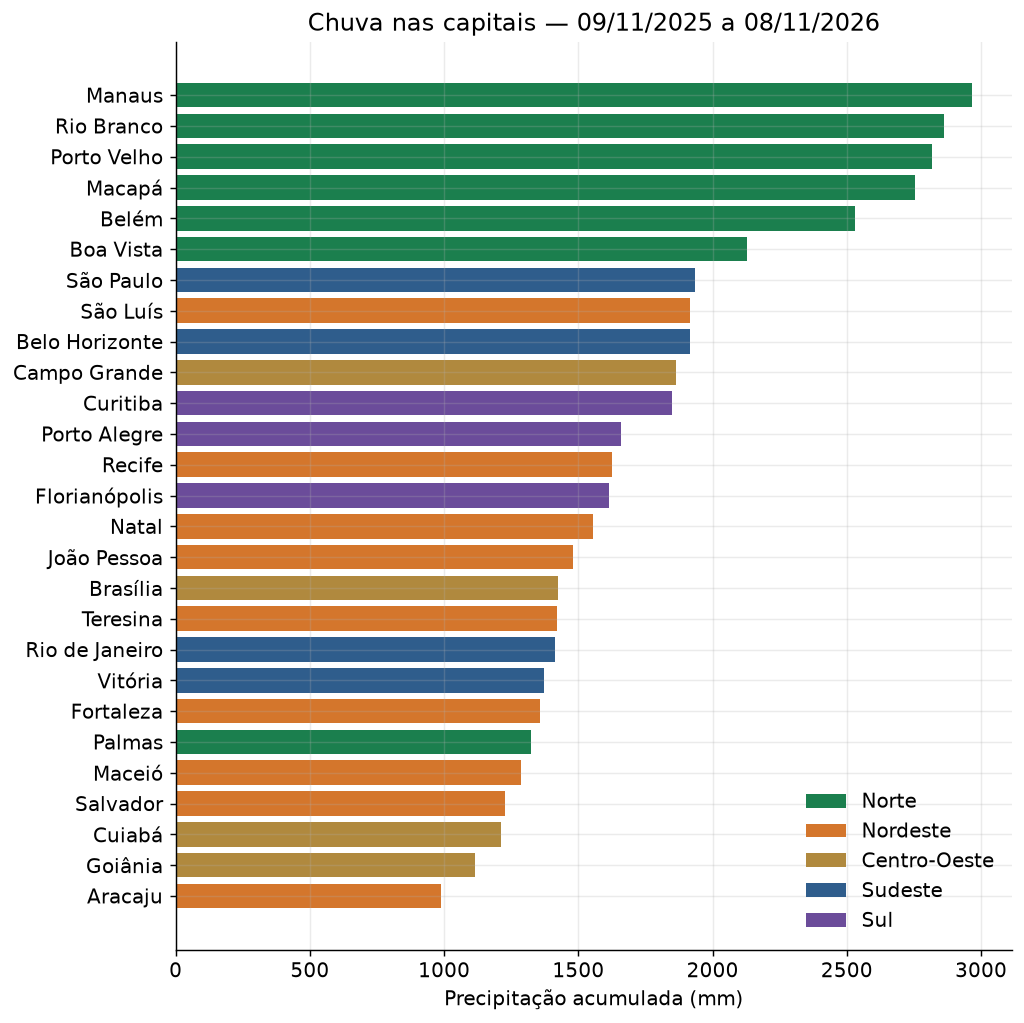

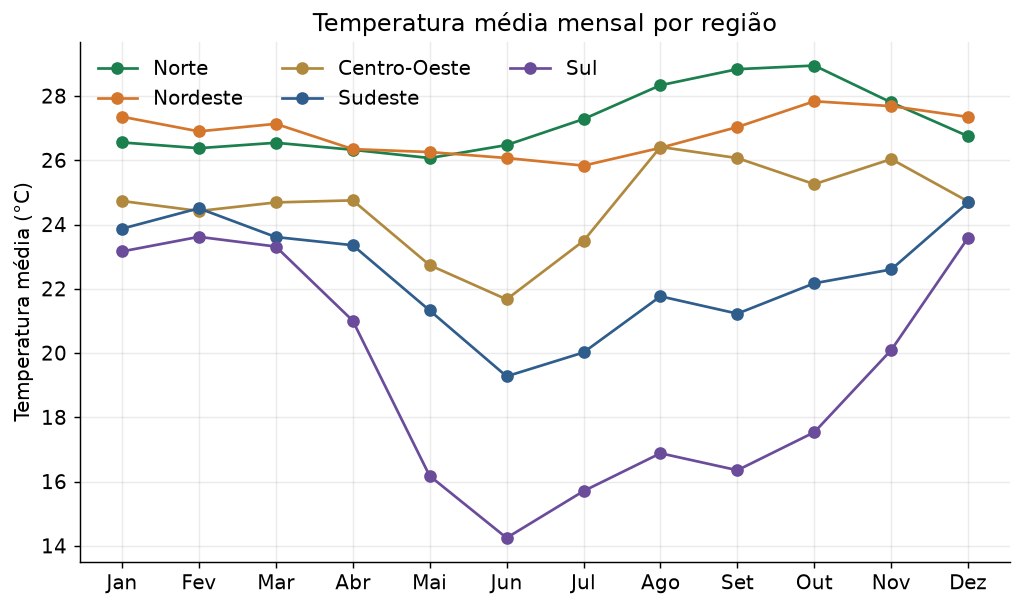

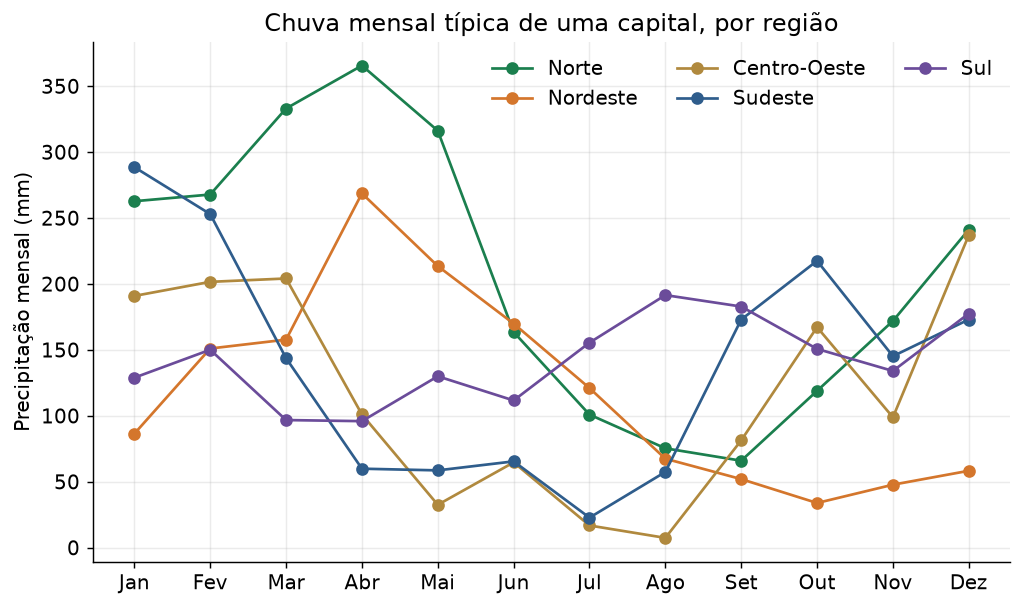

In [5]:
from matplotlib.patches import Patch

fig_dir = Path("figuras")
fig_dir.mkdir(exist_ok=True)
meses = ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun", "Jul", "Ago", "Set", "Out", "Nov", "Dez"]

fig, ax = plt.subplots(figsize=(8, 4.8))
caixas = [df.loc[df["regiao"] == regiao, "temp_media_c"] for regiao in ORDEM_REGIAO]
ax.boxplot(
    caixas,
    showfliers=True,
    flierprops={"marker": "o", "markersize": 2, "alpha": 0.35},
    medianprops={"color": "#222222", "linewidth": 1.5},
)
ax.set_xticks(range(1, len(ORDEM_REGIAO) + 1), ORDEM_REGIAO)
ax.set_ylabel("Temperatura média diária (°C)")
ax.set_title("Temperatura nas capitais, por região")
fig.tight_layout()
fig.savefig(fig_dir / "temperatura_por_regiao.png", dpi=130)
plt.show()

fig, ax = plt.subplots(figsize=(8, 8))
ranking = resumo.sort_values("precipitacao_mm", ascending=True)
ax.barh(
    ranking["cidade"],
    ranking["precipitacao_mm"],
    color=[CORES[regiao] for regiao in ranking["regiao"]],
)
ax.set_xlabel("Precipitação acumulada (mm)")
ax.set_title("Chuva nas capitais — 09/11/2025 a 08/11/2026")
ax.legend(
    handles=[Patch(facecolor=cor, label=regiao) for regiao, cor in CORES.items()],
    loc="lower right",
    frameon=False,
)
fig.tight_layout()
fig.savefig(fig_dir / "precipitacao_por_capital.png", dpi=130)
plt.show()

temp_mes = df.pivot_table(index="mes", columns="regiao", values="temp_media_c", aggfunc="mean")
fig, ax = plt.subplots(figsize=(8, 4.8))
for regiao in ORDEM_REGIAO:
    ax.plot(temp_mes.index, temp_mes[regiao], marker="o", color=CORES[regiao], label=regiao)
ax.set_xticks(range(1, 13), meses)
ax.set_ylabel("Temperatura média (°C)")
ax.set_title("Temperatura média mensal por região")
ax.legend(frameon=False, ncol=3)
fig.tight_layout()
fig.savefig(fig_dir / "temperatura_mensal.png", dpi=130)
plt.show()

soma_mes = df.groupby(["regiao", "cidade", "mes"], as_index=False)["precipitacao_mm"].sum()
chuva_mes = soma_mes.pivot_table(index="mes", columns="regiao", values="precipitacao_mm", aggfunc="mean")
fig, ax = plt.subplots(figsize=(8, 4.8))
for regiao in ORDEM_REGIAO:
    ax.plot(chuva_mes.index, chuva_mes[regiao], marker="o", color=CORES[regiao], label=regiao)
ax.set_xticks(range(1, 13), meses)
ax.set_ylabel("Precipitação mensal (mm)")
ax.set_title("Chuva mensal típica de uma capital, por região")
ax.legend(frameon=False, ncol=3)
fig.tight_layout()
fig.savefig(fig_dir / "precipitacao_mensal.png", dpi=130)
plt.show()


## 6. INSIGHTS

1. **O calor médio do país esconde dois climas.** A média das capitais foi 25,1 °C, mas o Norte ficou em 27,2 °C e o Sul em 19,3 °C. Teresina teve a maior média do ano (28,8 °C). Curitiba teve a menor (17,7 °C). No Sul, o inverno (15,6 °C) e o verão (23,5 °C) se afastam. No Norte, o inverno (27,4 °C) foi até um pouco mais quente que o verão (26,6 °C): ali o ano quase não esfria.

2. **Cada região tem o seu calendário de chuva.** Manaus acumulou 2.967 mm e Belém teve chuva em 89,6% dos dias. Aracaju ficou no outro extremo, com 989 mm. No Norte, a chuva se concentra de dezembro a maio. No Centro-Oeste, agosto praticamente secou (0,24 mm por dia). No Sul, agosto foi o mês mais úmido. O Sudeste acompanha o Centro-Oeste: verão chuvoso e inverno seco.

3. **O interior esquenta e esfria mais do que o litoral.** A amplitude térmica média foi de 9,5 °C no Centro-Oeste e de 5,7 °C no Nordeste. O dia mais quente da série foi 28/09/2026, em Cuiabá, com 40,0 °C. A madrugada mais fria foi 25/06/2026, em Curitiba, com 2,2 °C. O maior volume em 24 horas foi 114,2 mm, em Natal, em 21/07/2026.

## 7. LIMITAÇÕES

- Cada capital entra como um ponto, o centro da cidade, ajustado pela API ao ponto de grade do modelo. O valor vale para esse sítio.
- A fonte é reanálise (ERA5 via Open-Meteo), não a estação do INMET. Serve para comparar as cidades entre si.
- A janela tem um ano, o bastante para ver a estação. A comparação com a normal climatológica de 30 anos fica em aberto.
- Capital não representa o interior do estado. O Amazonas, Minas Gerais e a Bahia variam muito fora da capital.
- Novembro está completo em número de dias, mas mistura 2025 e 2026, porque a série tem 365 dias corridos.

## 8. PRÓXIMOS PASSOS

- Comparar este ano com as normais climatológicas do INMET, para separar o calendário habitual de um ano fora da curva.
- Acrescentar umidade e um índice simples de desconforto térmico.
- Repetir a mesma coleta por vários anos, para a média mensal deixar de depender de um único novembro ou de um único agosto.

## 9. CÓDIGO

A coleta, a limpeza, o processamento e os gráficos estão neste notebook. Os arquivos gerados são `dados/clima_capitais_bruto.csv`, `dados/clima_capitais.csv` e os PNG em `figuras/`.

Repositório: https://github.com/juliocesarv12/atvidade_2

## 10. REFERÊNCIAS

- OPEN-METEO. *Historical Weather API*. Disponível em: https://open-meteo.com/en/docs/historical-weather-api. Acesso em: 9 nov. 2026.
- HERSBACH, H. et al. The ERA5 global reanalysis. *Quarterly Journal of the Royal Meteorological Society*, v. 146, p. 1999–2049, 2020.
- IBGE. *Divisão regional do Brasil*. Rio de Janeiro: IBGE.
